# Inspect Pascal’s time-independent background models

This notebook explores the five version 3.00 normalizing-flow background models. We first inspect their metadata and domains; later we will examine their distributions and compare the relevant projection with Pascal’s reference.

The component-to-file mapping and the provenance of the stored rates remain to be verified. Loading a model does not validate its predictions.


In [1]:
%load_ext autoreload
%autoreload 2

## 1. Environment and imports

Check that the notebook uses the project environment with Pascal’s updated COSIpy.


In [2]:
import sys
print(sys.executable)

/Users/maura/Documents/COSI/cosi_background/cosipy-background-nf/.venv/bin/python


In [ ]:
from pathlib import Path
from cosipy.background_estimation.ml import NFBackground
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import torch
import subprocess
import h5py

%matplotlib inline


WARNING FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.



In [4]:
import gzip
import shutil

## 2. Load the first model

Start with part 01 to inspect one model before loading all five. The physical component associated with this file is provisional.


In [5]:
model_path = Path("../model/nfbackground_part-01_v3-00.fits")

print("File exists:", model_path.exists())

background = NFBackground(
    model_path,
    devices=["cpu"],
    density_compile_mode=None,
    show_progress=False,
)

print("Model version:", background._version)

File exists: True
Model version: 3.00


## 3. Inspect part 01 metadata

The checkpoint contains the density configuration and the input for the constant-rate model. `_ckpt` is an internal COSIpy attribute, used here for inspection.


In [6]:
print("Density configuration keys:")
print(background._ckpt["density_input"].keys())

print("\nRate input:")
print(background._ckpt["rate_input"])

Density configuration keys:
dict_keys(['model_state_dict', 'bins', 'hidden_units', 'residual_blocks', 'total_layers', 'menergy_cuts', 'phi_cuts', 'coefficients'])

Rate input:
{'counts': 97554902, 'livetime': np.float64(6579555.0)}


The energy and Phi cuts define the model domain. The constant rate is calculated from the stored counts and livetime; their provenance and selection must be checked before using the rate as a component weight. The density configuration’s `bins` parameter is internal to the normalizing flow, not CDS analysis binning.


In [7]:
density_input = background._ckpt["density_input"]
rate_input = background._ckpt["rate_input"]

print("Measured-energy limits:", density_input["menergy_cuts"], "keV")
print("Phi limits:", density_input["phi_cuts"], "radians")
print("Constant rate:", rate_input["counts"] / rate_input["livetime"], "events/s")

Measured-energy limits: [100, 10000] keV
Phi limits: [0.0, 3.141592653589793] radians
Constant rate: 14.826975684525777 events/s


## 4. Inspect all five models

Load each file separately and compare its version, domain, counts, livetime, and constant rate. The models are stored in `models` for later exploration; no component weights or combined prediction are assumed.


In [8]:
models = {}

for part in range(1, 6):
    model_path = Path(f"../model/nfbackground_part-{part:02d}_v3-00.fits")

    model = NFBackground(
        model_path,
        devices=["cpu"],
        density_compile_mode=None,
        show_progress=False,
    )

    models[part] = model

    density = model._ckpt["density_input"]
    rate = model._ckpt["rate_input"]

    print(f"\nPart {part:02d}")
    print(f"  Version: {model._version}")
    print(f"  Energy limits: {density['menergy_cuts']} keV")
    print(f"  Phi limits: {density['phi_cuts']} radians")
    print(f"  Counts: {rate['counts']:,}")
    print(f"  Livetime: {rate['livetime']:,.0f} s")
    print(f"  Constant rate: {rate['counts'] / rate['livetime']:.3f} events/s")


Part 01
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 97,554,902
  Livetime: 6,579,555 s
  Constant rate: 14.827 events/s

Part 02
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 27,081,364
  Livetime: 6,579,555 s
  Constant rate: 4.116 events/s

Part 03
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 6,176,355
  Livetime: 6,579,555 s
  Constant rate: 0.939 events/s

Part 04
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 25,705,670
  Livetime: 6,579,555 s
  Constant rate: 3.907 events/s

Part 05
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 4,958,885
  Livetime: 6,579,555 s
  Constant rate: 0.754 events/s


## 5. Component 01: candidate EGB photons

Compare the simulated cosmic-photon events with the part 01 model. The file-to-component mapping remains provisional.


### 5.1. Simulated cosmic-photon background

Inspect the candidate reference event file and its columns, then build a normalized measured-energy and scattering-angle projection. The matching event count supports the proposed correspondence with part 01 but does not establish its training provenance.


In [9]:
egb_path = Path(
    "../data/background_components/"
    "CosmicPhotons_3months_unbinned_data_filtered_with_SAAcut.fits.gz"
)

print("File exists:", egb_path.exists())

with fits.open(egb_path) as hdul:
    hdul.info()

File exists: True
Filename: ../data/background_components/CosmicPhotons_3months_unbinned_data_filtered_with_SAAcut.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     45   97554902R x 11C   [D, D, 2D, 2D, 2D, D, D, D, D, D, D]   


In [10]:
with fits.open(egb_path) as hdul:
    print(hdul[1].columns)

ColDefs(
    name = 'Energies'; format = 'D'; unit = 'keV'
    name = 'TimeTags'; format = 'D'; unit = 's'
    name = 'Xpointings (glon,glat)'; format = '2D'; unit = 'rad'; dim = '(2)'
    name = 'Ypointings (glon,glat)'; format = '2D'; unit = 'rad'; dim = '(2)'
    name = 'Zpointings (glon,glat)'; format = '2D'; unit = 'rad'; dim = '(2)'
    name = 'Phi'; format = 'D'; unit = 'rad'
    name = 'Chi local'; format = 'D'; unit = 'rad'
    name = 'Psi local'; format = 'D'; unit = 'rad'
    name = 'Distance'; format = 'D'; unit = 'cm'
    name = 'Chi galactic'; format = 'D'; unit = 'deg'
    name = 'Psi galactic'; format = 'D'; unit = 'deg'
)


#### Prepare and check the uncompressed file

Use the existing uncompressed file when available and check that the FITS table fits within it before histogramming. A size check does not verify all event values.


In [11]:
egb_uncompressed_path = egb_path.with_suffix("")

print("Uncompressed file exists:", egb_uncompressed_path.exists())

Uncompressed file exists: True


In [12]:
if egb_uncompressed_path.exists():
    print("Using existing file:", egb_uncompressed_path)
else:
    with gzip.open(egb_path, "rb") as compressed:
        with egb_uncompressed_path.open("xb") as uncompressed:
            shutil.copyfileobj(compressed, uncompressed, length=1024 * 1024)

    print("Created:", egb_uncompressed_path)

Using existing file: ../data/background_components/CosmicPhotons_3months_unbinned_data_filtered_with_SAAcut.fits


In [13]:
with fits.open(egb_uncompressed_path, memmap=True) as hdul:
    hdul.info()

    table_info = hdul.fileinfo(1)
    expected_end = table_info["datLoc"] + table_info["datSpan"]
    actual_size = egb_uncompressed_path.stat().st_size

    print(f"\nFile size: {actual_size:,} bytes")
    print(f"End of FITS table: {expected_end:,} bytes")
    print("Table fits within file:", actual_size >= expected_end)

if actual_size < expected_end:
    raise ValueError("The uncompressed FITS table is incomplete.")


Filename: ../data/background_components/CosmicPhotons_3months_unbinned_data_filtered_with_SAAcut.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     45   97554902R x 11C   [D, D, 2D, 2D, 2D, D, D, D, D, D, D]   

File size: 10,926,158,400 bytes
End of FITS table: 10,926,158,400 bytes
Table fits within file: True


#### Build the simulation projection

Read the uncompressed table in chunks and count events in measured-energy and scattering-angle bins. All events in the file are included without a time selection, so the result is integrated over the file’s observation period. The bins are exploratory; Pascal’s exact plot binning has not been confirmed.


In [14]:
energy_edges = np.geomspace(100, 10_000, 1001)  # keV
phi_edges = np.linspace(0, 180, 361)           # degrees

egb_counts = np.zeros(
    (len(energy_edges) - 1, len(phi_edges) - 1),
    dtype=np.int64,
)

chunk_size = 1_000_000

with fits.open(egb_uncompressed_path, memmap=True) as hdul:
    events = hdul[1].data
    n_events = len(events)

    for start in range(0, n_events, chunk_size):
        chunk = events[start:start + chunk_size]

        counts, _, _ = np.histogram2d(
            chunk["Energies"],
            np.rad2deg(chunk["Phi"]),
            bins=(energy_edges, phi_edges),
        )
        egb_counts += counts.astype(np.int64)

print(f"Events in file: {n_events:,}")
print(f"Events in histogram: {egb_counts.sum():,}")
print(f"Events outside histogram: {n_events - egb_counts.sum():,}")

Events in file: 97,554,902
Events in histogram: 97,554,902
Events outside histogram: 0


#### Plot the normalized simulation

Normalize by the event total and bin area to show a probability density in keV⁻¹ deg⁻¹. Empty bins and values at the low end of the color scale are both shown in dark purple; the display does not alter the counts.


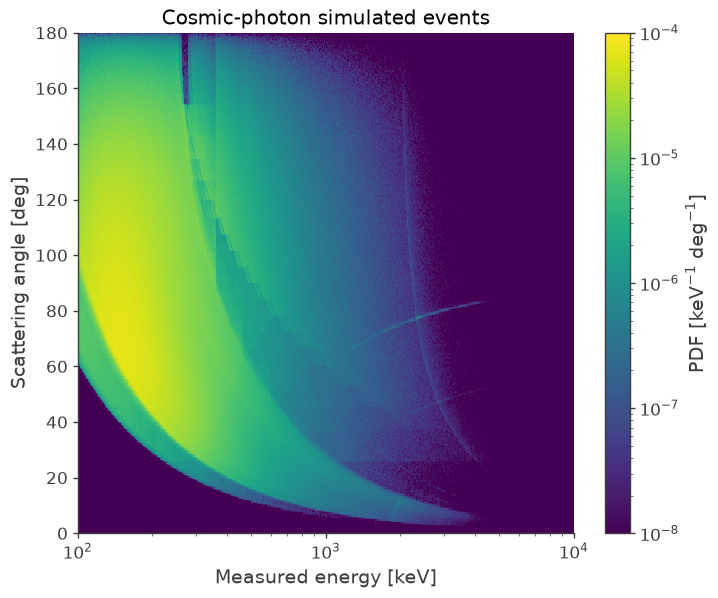

In [19]:
bin_areas = np.diff(energy_edges)[:, None] * np.diff(phi_edges)[None, :]
egb_density = egb_counts / egb_counts.sum() / bin_areas

fig, ax = plt.subplots(figsize=(8, 6.5))

cmap = plt.colormaps["viridis"].copy()
cmap.set_bad(cmap(0))
mesh = ax.pcolormesh(
    energy_edges,
    phi_edges,
    egb_density.T,
    norm=LogNorm(vmin=1e-8, vmax=1e-4),
    cmap=cmap,
    shading="auto",
)

ax.set_xscale("log")
ax.set_xlabel("Measured energy [keV]")
ax.set_ylabel("Scattering angle [deg]")
ax.set_title("Cosmic-photon simulated events")

fig.colorbar(mesh, ax=ax, label=r"PDF [keV$^{-1}$ deg$^{-1}$]")


### 5.2. Normalizing-flow background: component 01

The small sampling test below launches [the sampling script](../src/sample_time_independent_background.py) in a separate process to protect the notebook kernel from COSIpy multiprocessing. A full-size component 01 sample is generated separately from the terminal; do not read it until sampling has finished and its completed count has been checked.

The NF describes a continuous, time-independent CDS shape. Next we will histogram its sampled measured energy and scattering angle using the simulation’s bin edges. Sampling precision depends on sample size. Expected counts require a suitable normalization and livetime; the part 01 to cosmic-photon mapping remains provisional.


In [ ]:
test_output = Path("../data/NF_background/part-01_notebook_test.hdf5")

if test_output.exists():
    with h5py.File(test_output, "r") as sample_file:
        completed = sample_file.attrs.get("completed_samples", 0)
        requested = sample_file.attrs.get("requested_samples", 0)
        if completed != 100 or requested != 100 or sample_file.attrs.get("part") != 1:
            raise ValueError("Existing test output is incomplete or does not match this test.")
    print("Using existing complete test sample:", test_output)
else:
    result = subprocess.run(
        [
            sys.executable,
            "../src/sample_time_independent_background.py",
            "--part", "1",
            "--samples", "100",
            "--output", str(test_output),
        ],
        capture_output=True,
        text=True,
    )
    print("Return code:", result.returncode)
    print("Output:\n", result.stdout)
    print("Errors:\n", result.stderr)
    result.check_returncode()


Return code: 0
Output:
 Sampled 100 / 100 events
Saved ../data/NF_background/part-01_notebook_test.hdf5

Errors:
 
WARNING FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.


WARNING FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.


